# 04 · Análisis bivariado: actividad de los colectivos y calidad del aire

**Idea central.** Si los colectivos (diésel) aportan una parte importante del NOx, entonces cuanto menos
circulan, más tendría que bajar el NOx **respecto del CO** (que viene sobre todo de autos a nafta).
Antes de mirar los paros uno por uno (notebook 05), miramos **todos los días** del período: hábiles, sábados,
domingos, feriados y paros forman un **gradiente natural de actividad**.

**Variables:**
- `actividad_colectivo_vs_habil`: usos SUBE de los colectivos que circulan por CABA ese día, dividido por un
  día hábil normal típico de las 4 semanas anteriores y posteriores (1 = día hábil normal; 0,35 = domingo).
- `nox_co_816`: cociente NOx (ppb) / CO (ppm) en el bloque 8-16 h, la **firma diésel**.
- Meteorología diaria del SMN: viento, temperatura, humedad y lluvia.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Dónde están los Parquet: export/ del repo (local, después de `uv run python run.py`)
# o la carpeta actual (Colab: subir los .parquet de export/ con el panel de archivos).
for BASE in [Path("../export"), Path("export"), Path(".")]:
    if (BASE / "gold_analitico.parquet").exists():
        break
else:
    raise FileNotFoundError("No encuentro gold_analitico.parquet: corré `uv run python run.py` o subilo a Colab")

d = pd.read_parquet(BASE / "gold_analitico.parquet")
d["fecha"] = pd.to_datetime(d["fecha"])
eventos = pd.read_parquet(BASE / "eventos.parquet")
eventos["fecha"] = pd.to_datetime(eventos["fecha"])

ESTACIONES = ["CENTENARIO", "CORDOBA", "LA BOCA"]
# Un color fijo por estación en todos los notebooks (paleta validada para daltonismo).
COLOR = {"CENTENARIO": "#2a78d6", "CORDOBA": "#eb6834", "LA BOCA": "#1baf7a"}
# Resaltado de eventos (solo en gráficos donde no se colorea por estación).
COLOR_EVENTO = {"sin_colectivos": "#6250d6", "control": "#eda100"}
GRIS, TINTA, TINTA_2 = "#b9b8b2", "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "figure.dpi": 110, "font.size": 10, "text.color": TINTA,
    "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 11,
    "lines.linewidth": 2, "legend.frameon": False,
})
pd.options.display.float_format = "{:,.2f}".format
print(f"{len(d):,} filas (estación × día), {d.fecha.min():%d/%m/%Y} a {d.fecha.max():%d/%m/%Y}")

2,950 filas (estación × día), 01/01/2024 a 30/09/2026


## 1. Grupos de días

- **Hábil normal:** hábil, no feriado y con tren, subte y colectivos funcionando como siempre. Es la referencia.
- **Hábil atípico:** hábil pero con actividad baja (puentes, vacaciones de invierno, fiestas).
- **Paro sin colectivos:** los 4 paros con más del 60% de las líneas paradas.
- **Paro con colectivos (control):** paros donde los colectivos funcionaron.

In [2]:
GRUPOS = ["Hábil normal", "Hábil atípico", "Paro con colectivos", "Sábado", "Feriado", "Domingo",
          "Paro sin colectivos"]
d["grupo"] = np.select(
    [d.grupo_evento == "sin_colectivos", d.grupo_evento == "control",
     (d.tipo_dia == "hábil") & d.es_dia_normal,
     d.tipo_dia == "hábil", d.tipo_dia == "sábado", d.tipo_dia == "domingo", d.tipo_dia == "feriado"],
    ["Paro sin colectivos", "Paro con colectivos", "Hábil normal", "Hábil atípico", "Sábado", "Domingo", "Feriado"],
    default="otro")
d.groupby("grupo").agg(estacion_dias=("fecha", "size"), dias=("fecha", "nunique"),
                       actividad_mediana=("actividad_colectivo_vs_habil", "median")).reindex(GRUPOS)

,estacion_dias,dias,actividad_mediana
grupo,,,
Hábil normal,1633,553,1.00
Hábil atípico,339,115,0.87
Paro con colectivos,6,2,0.75
Sábado,403,139,0.60
Feriado,157,53,0.36
Domingo,400,138,0.35
Paro sin colectivos,12,4,0.21


## 2. El gradiente: menos colectivos, menos firma diésel

Para que la comparación sea justa, cada día se compara **con su propia estación** (La Boca tiene un NOx/CO
mucho más alto que las otras dos, y los paros de 2024 solo tienen datos ahí). El índice es la media geométrica
del grupo dividida por la de los días hábiles normales de la misma estación, promediado entre estaciones
(**hábil normal = 100**).

In [3]:
VARS = {"nox_816_ppb": "NOx", "co_816_ppm": "CO", "nox_co_816": "NOx/CO"}
filas = []
for col, nombre in VARS.items():
    x = d[d[col] > 0].copy()
    x["log"] = np.log(x[col])
    ref = x[x.grupo == "Hábil normal"].groupby("estacion")["log"].mean()
    x["desvio"] = x["log"] - x["estacion"].map(ref)
    # promedio dentro de cada estación y después entre estaciones (cada estación pesa igual)
    por_est = x.groupby(["grupo", "estacion"])["desvio"].mean()
    filas.append((np.exp(por_est.groupby("grupo").mean()) * 100).rename(nombre))
indice = pd.concat(filas, axis=1).reindex(GRUPOS)
indice.insert(0, "actividad", d.groupby("grupo")["actividad_colectivo_vs_habil"].median().reindex(GRUPOS))
indice.insert(1, "viento (km/h)", d.drop_duplicates("fecha").groupby("grupo")["viento_kmh"].median().reindex(GRUPOS))
indice.style.format({"actividad": "{:.2f}", "viento (km/h)": "{:.1f}", "NOx": "{:.0f}", "CO": "{:.0f}", "NOx/CO": "{:.0f}"})

,actividad,viento (km/h),NOx,CO,NOx/CO
grupo,,,,,
Hábil normal,1.00,10.5,100,100,100
Hábil atípico,0.87,11.0,98,104,96
Paro con colectivos,0.75,15.5,61,80,77
Sábado,0.60,11.0,71,85,84
Feriado,0.36,10.5,51,72,71
Domingo,0.35,11.0,45,69,64
Paro sin colectivos,0.21,12.5,68,116,57


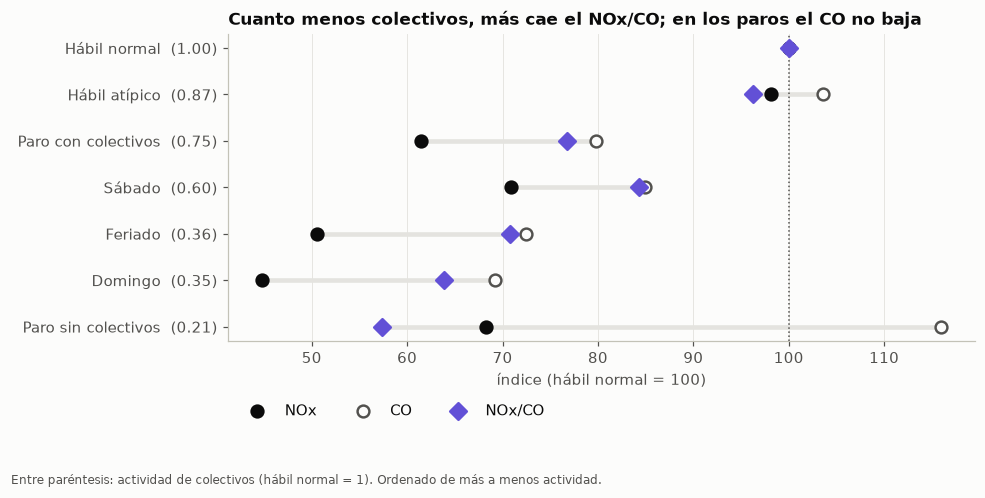

In [4]:
orden = indice.sort_values("actividad", ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.2))
y = np.arange(len(orden))[::-1]
MARCAS = {"NOx": ("o", TINTA, TINTA), "CO": ("o", "#fcfcfb", TINTA_2), "NOx/CO": ("D", "#6250d6", "#6250d6")}
for nombre, (m, cara, borde) in MARCAS.items():
    ax.scatter(orden[nombre], y, marker=m, s=60, facecolor=cara, edgecolor=borde, linewidth=1.6,
               label=nombre, zorder=3)
for yi, (_, fila) in zip(y, orden.iterrows()):
    ax.plot([fila[list(MARCAS)].min(), fila[list(MARCAS)].max()], [yi, yi], color="#e4e3df", lw=3, zorder=1)
ax.axvline(100, color=TINTA_2, lw=1, ls=":")
ax.set_yticks(y, [f"{g}  ({a:.2f})" for g, a in zip(orden.index, orden.actividad)])
ax.set_xlabel("índice (hábil normal = 100)")
ax.set_title("Cuanto menos colectivos, más cae el NOx/CO; en los paros el CO no baja")
ax.legend(loc="lower left", ncol=3, bbox_to_anchor=(0, -0.3))
ax.grid(axis="y", visible=False)
fig.text(0.01, -0.06, "Entre paréntesis: actividad de colectivos (hábil normal = 1). Ordenado de más a menos actividad.",
         fontsize=8, color=TINTA_2)
plt.tight_layout()

**Lectura.**
- **Fines de semana y feriados:** baja todo (hay menos autos y menos colectivos y camiones), pero el NOx baja
  más que el CO. El domingo: NOx −55%, CO −31%, NOx/CO −36%.
- **Paros sin colectivos:** el patrón cambia. El NOx baja (−32%) pero **el CO sube (+16%)**. Es consistente con
  que la gente reemplace el colectivo por auto, taxi o remís: más nafta, menos diésel. El resultado es que el
  **NOx/CO cae más que en cualquier otro tipo de día (−43%)**, aunque el NOx solo no caiga tanto como un domingo.
  Lo mismo encontraron en Barcelona (González, Perdiguero y Sanz, 2021): con paro de colectivos, CO +12%.
- **Paros con colectivos (control):** el NOx también cae, pero fueron días ventosos (15,5 km/h de mediana contra
  10,5 de un hábil normal). El NOx/CO cae bastante menos (−23%).
- **Cuidado:** los paros sin colectivos son 4 días (12 combinaciones estación-día) y esta tabla no descuenta
  la meteorología. Es una pista fuerte, no una conclusión.

## 3. Día por día: actividad contra firma diésel

Cada punto es una estación y un día. La línea es la mediana por tramos de actividad. Los eventos están
resaltados: **violeta** = paro sin colectivos, **amarillo** = paro con colectivos (control).

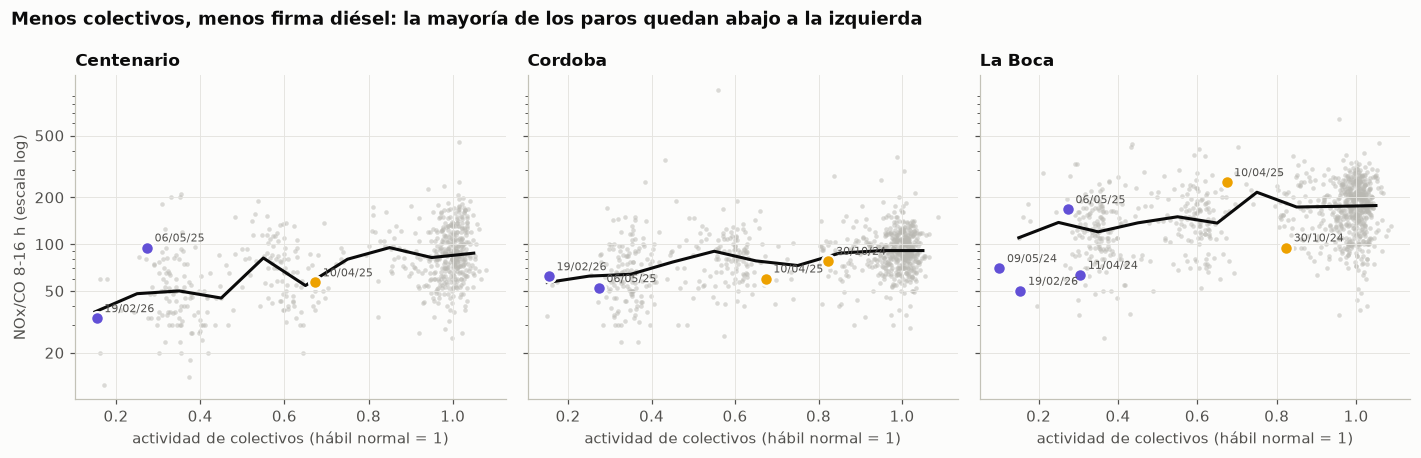

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
tramos = np.arange(0.1, 1.25, 0.1)
for ax, est in zip(axes, ESTACIONES):
    s = d[(d.estacion == est) & (d.nox_co_816 > 0)].dropna(subset=["actividad_colectivo_vs_habil"])
    ax.scatter(s.actividad_colectivo_vs_habil, s.nox_co_816, s=9, color=GRIS, alpha=0.5, linewidths=0)
    med = s.groupby(pd.cut(s.actividad_colectivo_vs_habil, tramos), observed=True)["nox_co_816"].agg(["median", "size"])
    med = med[med["size"] >= 5]
    ax.plot([i.mid for i in med.index], med["median"], color=TINTA, lw=2)
    for grupo, color in COLOR_EVENTO.items():
        ev = s[s.grupo_evento == grupo]
        ax.scatter(ev.actividad_colectivo_vs_habil, ev.nox_co_816, s=70, color=color, edgecolor="#fcfcfb",
                   linewidth=1.5, zorder=3)
        for _, r in ev.iterrows():
            ax.annotate(f"{r.fecha:%d/%m/%y}", (r.actividad_colectivo_vs_habil, r.nox_co_816),
                        xytext=(5, 4), textcoords="offset points", fontsize=7.5, color=TINTA_2)
    ax.set_yscale("log")
    ax.set_yticks([20, 50, 100, 200, 500], [20, 50, 100, 200, 500])
    ax.yaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_title(est.title())
    ax.set_xlabel("actividad de colectivos (hábil normal = 1)")
axes[0].set_ylabel("NOx/CO 8-16 h (escala log)")
fig.suptitle("Menos colectivos, menos firma diésel: la mayoría de los paros quedan abajo a la izquierda",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

In [6]:
from scipy.stats import spearmanr
print("Correlación de Spearman entre actividad y NOx/CO, todos los días:")
for est in ESTACIONES:
    s = d[(d.estacion == est)].dropna(subset=["actividad_colectivo_vs_habil", "nox_co_816"])
    rho, p = spearmanr(s.actividad_colectivo_vs_habil, s.nox_co_816)
    print(f"  {est:11s} rho = {rho:.2f}  (n = {len(s)}, p = {p:.1g})")

Correlación de Spearman entre actividad y NOx/CO, todos los días:
  CENTENARIO  rho = 0.41  (n = 641, p = 3e-27)
  CORDOBA     rho = 0.29  (n = 792, p = 1e-16)
  LA BOCA     rho = 0.27  (n = 911, p = 5e-17)


## 4. El otro factor: el viento

El viento diluye todo lo que se emite. Si un paro coincide con un día ventoso, el NOx baja aunque no haya
cambiado nada en el tránsito. ¿Cuánto afecta el viento a cada variable? Solo días hábiles normales, para que
la actividad sea la misma.

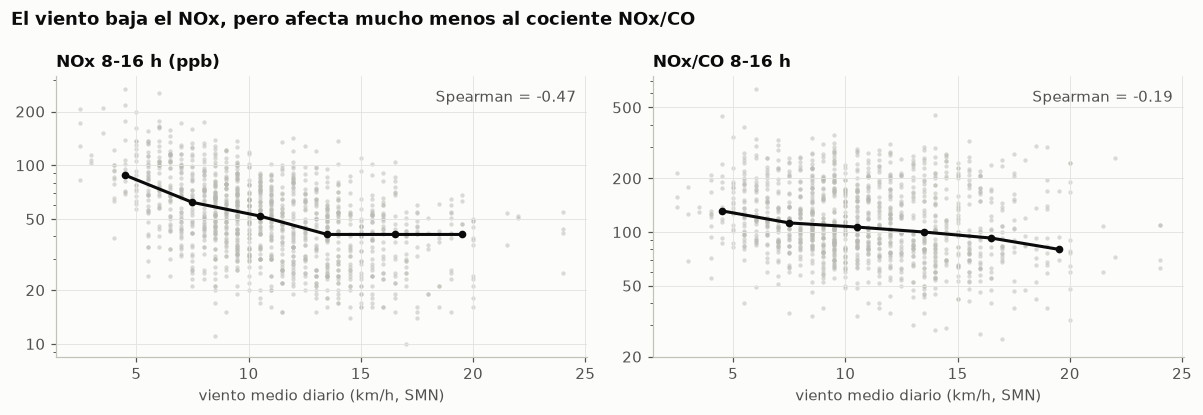

In [7]:
from matplotlib.ticker import NullFormatter
normales = d[d.grupo == "Hábil normal"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
tramos_v = np.arange(0, 32, 3)
for ax, (col, nombre) in zip(axes, [("nox_816_ppb", "NOx 8-16 h (ppb)"), ("nox_co_816", "NOx/CO 8-16 h")]):
    s = normales[normales[col] > 0].dropna(subset=["viento_kmh"])
    ax.scatter(s.viento_kmh, s[col], s=8, color=GRIS, alpha=0.5, linewidths=0)
    med = s.groupby(pd.cut(s.viento_kmh, tramos_v), observed=True)[col].agg(["median", "size"])
    med = med[med["size"] >= 10]
    ax.plot([i.mid for i in med.index], med["median"], color=TINTA, lw=2, marker="o", markersize=4)
    ax.set_yscale("log")
    ax.set(xlabel="viento medio diario (km/h, SMN)", title=nombre)
    ax.yaxis.set_minor_formatter(NullFormatter())
    rho, _ = spearmanr(s.viento_kmh, s[col])
    ax.text(0.98, 0.95, f"Spearman = {rho:.2f}", transform=ax.transAxes, ha="right", va="top", color=TINTA_2)
axes[0].set_yticks([10, 20, 50, 100, 200], [10, 20, 50, 100, 200])
axes[1].set_yticks([20, 50, 100, 200, 500], [20, 50, 100, 200, 500])
fig.suptitle("El viento baja el NOx, pero afecta mucho menos al cociente NOx/CO", x=0.01, ha="left",
             fontweight="bold")
plt.tight_layout()

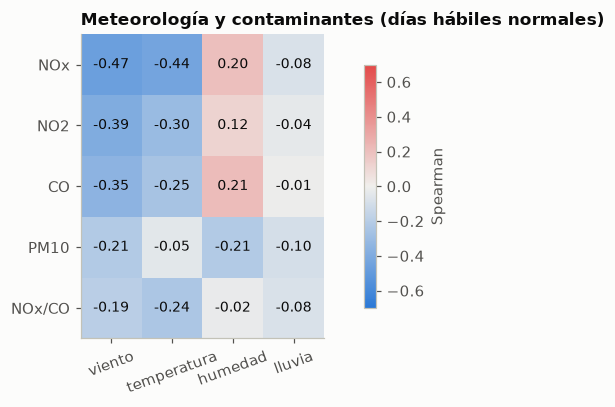

In [8]:
# Correlaciones de Spearman en días hábiles normales (rango: -1 a 1).
CONT = {"nox_816_ppb": "NOx", "no2_816_ppb": "NO2", "co_816_ppm": "CO", "pm10_816_ugm3": "PM10", "nox_co_816": "NOx/CO"}
METEO = {"viento_kmh": "viento", "temp_c": "temperatura", "humedad_pct": "humedad", "precipitacion_mm": "lluvia"}
corr = normales[list(CONT) + list(METEO)].corr(method="spearman").loc[list(CONT), list(METEO)]
corr = corr.rename(index=CONT, columns=METEO)

from matplotlib.colors import LinearSegmentedColormap
divergente = LinearSegmentedColormap.from_list("azul_rojo", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(7.5, 3.8))
im = ax.imshow(corr.values, cmap=divergente, vmin=-0.7, vmax=0.7)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=20)
ax.set_yticks(range(len(corr.index)), corr.index)
ax.grid(False)
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9, color=TINTA)
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman")
ax.set_title("Meteorología y contaminantes (días hábiles normales)")
plt.tight_layout()

**Lectura.**
- Con más viento baja todo: NOx, NO2 y CO (Spearman entre −0,35 y −0,47). Con más temperatura también bajan
  (el invierno acumula contaminación, ver notebook 01).
- El **NOx/CO depende mucho menos del viento** (−0,19): el viento diluye por igual al NOx y al CO, así que el
  cociente se mantiene. Por eso es mejor indicador que el NOx solo para comparar días con distinta meteorología.
- Pero el cociente **no es inmune**: todavía depende algo del viento y de la temperatura (−0,24). Hay que
  ajustar igual, y eso hace el modelo del notebook 05.

## 5. Los eventos, comparación cruda

Cada evento contra la **mediana de los días hábiles normales del mismo mes y la misma estación**.
Es una comparación **sin ajustar por meteorología**: sirve para ver el orden de magnitud, no para concluir.
El ajuste por viento, temperatura y lluvia, con la prueba placebo, está en `05_eventos`.

In [9]:
ref = (d[d.grupo == "Hábil normal"].assign(periodo=lambda x: x.fecha.dt.to_period("M"))
         .groupby(["estacion", "periodo"])[list(VARS)].median())
ev = d[d.grupo_evento.notna()].assign(periodo=lambda x: x.fecha.dt.to_period("M"))
filas = []
for _, r in ev.iterrows():
    base = ref.loc[(r.estacion, r.periodo)]
    fila = {"fecha": r.fecha.date(), "evento": r.evento, "grupo": r.grupo_evento, "estación": r.estacion.title(),
            "actividad": r.actividad_colectivo_vs_habil, "viento": r.viento_kmh, "lluvia": r.precipitacion_mm}
    for col, nombre in VARS.items():
        fila[f"{nombre} %"] = (r[col] / base[col] - 1) * 100 if pd.notna(r[col]) else np.nan
    filas.append(fila)
crudo = pd.DataFrame(filas).sort_values(["grupo", "fecha", "estación"], ascending=[False, True, True])
crudo.round(1)

,fecha,evento,grupo,estación,actividad,viento,lluvia,NOx %,CO %,NOx/CO %
14,2024-04-11,Paro UTA,sin_colectivos,Centenario,0.30,15.50,0.00,NaN,0.00,NaN
8,2024-04-11,Paro UTA,sin_colectivos,Cordoba,0.30,15.50,0.00,-3.10,NaN,NaN
2,2024-04-11,Paro UTA,sin_colectivos,La Boca,0.30,15.50,0.00,-43.30,0.00,-37.40
12,2024-05-09,Paro general CGT,sin_colectivos,Centenario,0.10,7.50,0.00,NaN,0.00,NaN
6,2024-05-09,Paro general CGT,sin_colectivos,Cordoba,0.10,7.50,0.00,-28.30,NaN,NaN
0,2024-05-09,Paro general CGT,sin_colectivos,La Boca,0.10,7.50,0.00,-31.10,33.30,-43.70
17,2025-05-06,Paro UTA,sin_colectivos,Centenario,0.30,9.50,11.10,-9.50,-11.10,-10.00
11,2025-05-06,Paro UTA,sin_colectivos,Cordoba,0.30,9.50,11.10,-17.50,11.10,-45.30
5,2025-05-06,Paro UTA,sin_colectivos,La Boca,0.30,9.50,11.10,-14.60,0.00,-16.20
13,2026-02-19,Paro general CGT,sin_colectivos,Centenario,0.20,15.50,0.30,-58.30,-25.00,-47.40


In [10]:
print("Mediana de los cambios (%), por grupo de evento:")
crudo.groupby("grupo")[[f"{n} %" for n in VARS.values()]].median().round(0)

Mediana de los cambios (%), por grupo de evento:


,NOx %,CO %,NOx/CO %
grupo,,,
control,-33.00,-24.00,-28.00
sin_colectivos,-23.00,0.00,-41.00


**Lectura.** Sin ajustar, en los paros sin colectivos el NOx/CO cae 41% (mediana) y en los controles, 28%.
Hay diferencia, pero menos de la que sugiere el gradiente: los controles también bajan porque fueron días
ventosos, y el 10/04/2025 fue paro general (probablemente circularon menos camiones). El paro con lluvia
(06/05/2025) muestra poco efecto. **Esta tabla no alcanza para concluir**: hace falta comparar cada evento
contra lo que se esperaba para ese día según su meteorología (notebook 05).

## Hallazgos

1. **Hay un gradiente:** a menos actividad de colectivos, menor NOx/CO, en las tres estaciones
   (Spearman entre actividad y NOx/CO de 0,27 a 0,41).
2. **Los paros sin colectivos tienen la firma diésel más baja de todos los tipos de día** (NOx/CO −43% contra un
   hábil normal), menor incluso que un domingo (−36%), aunque circula más gente.
3. **En los paros el CO sube (+16%)** mientras el NOx baja: consistente con un reemplazo del colectivo por autos.
   Esto explica por qué en Europa los paros de transporte público empeoran el aire y acá conviene mirar el
   cociente y no solo el NOx.
4. **El viento es el principal factor de confusión:** baja mucho el NOx y bastante menos el NOx/CO. Los días
   de control fueron ventosos, y eso explica buena parte de su caída.
5. **Comparación cruda de los eventos:** NOx/CO −41% en paros sin colectivos contra −28% en controles. La
   diferencia va en la dirección de la hipótesis, pero sin ajustar por meteorología no se puede afirmar.

**Siguiente:** `05_eventos` ajusta por viento, temperatura, lluvia, mes y día de la semana, y prueba si la
caída de cada paro es rara comparada con días normales (prueba placebo).